# Bildung in Deutschland 2006 bis 2026: Beschreibung, Bewertung und Handlungsbedarf

## Worum es geht

Dieses Notebook ordnet jeden Satz der elf Bildungsberichte einer von drei Kategorien zu: Beschreibung, Bewertung oder Handlungsbedarf. Damit beantwortet es Forschungsfrage 3 und legt die Grundlage für Forschungsfrage 2:

- Forschungsfrage 3: Wie verteilen sich Beschreibung, Bewertung und Handlungsbedarf im Text?
- Forschungsfrage 2, erster Teil: Welche Herausforderungen benennt der Bericht wiederholt?

Die Sätze mit Handlungsbedarf sind die Herausforderungen, die der Bericht benennt. Jeder Satz erbt das Hauptthema seines Absatzes aus dem Structural Topic Model in `02_stm_modell.ipynb`. So zeigt sich, zu welchen Themen der Bericht über 20 Jahre wiederholt Handlungsbedarf sieht. Den zweiten Teil von Forschungsfrage 2, den Abgleich mit den Indikatoren, rechnet `05_indikatoren.ipynb` auf Grundlage des Tabellenbestands aus `04_tabellenbestand.ipynb`.

## Inhalt dieses Notebooks

| Teil | Abschnitte | Frage |
|---|---|---|
| Daten | 1: Sätze bilden | Welche Einheit wird eingeordnet? |
| Einordnung | 2 bis 3: Wörterbuch, vorbereitete Handcodierung | Wie ordnet das Wörterbuch die Sätze ein, und wie lässt es sich prüfen? |
| Forschungsfrage 3 | 4: Anteile über die Zeit, Abbildungen 7 bis 9 | Wird der Bericht über 20 Jahre wertender? In welchen Kapiteln steht Handlungsbedarf? |
| Forschungsfrage 2 | 5 bis 7: Handlungsbedarf nach Thema, Robustheit, Gegenprobe ohne Signalwörter, Abbildungen 10 und 11 | Zu welchen Themen benennt der Bericht wiederholt Handlungsbedarf? |

Am Ende steht eine Zusammenfassung aller Entscheidungen, Befunde und Grenzen. Die Abbildungen setzen die Nummerierung aus `02_stm_modell.ipynb` fort, damit der Gesamtbericht sie unverändert übernehmen kann.

## Voraussetzungen

- `01_vorverarbeitung.ipynb` ist gelaufen und hat `data/interim/udpipe_gsd.rds`, `dokumente.rds` und `stm_daten.rds` erzeugt.
- `02_stm_modell.ipynb` ist gelaufen und hat `data/interim/stm_k40.rds` und `data/processed/stm_themen_k40_namen.csv` erzeugt.
- R 4.6.1 mit den Paketen `dplyr`, `tidyr`, `ggplot2`, `readxl` und `writexl`. Die erste Zelle installiert fehlende Pakete.

## Laufzeit und Textauszüge

Ein vollständiger Lauf dauert wenige Minuten. Nur die Gegenprobe in Abschnitt 7 schätzt beim ersten Lauf ein Modell neu, das dauert einige Minuten (im ersten Lauf 5 Minuten). Das Notebook gibt keine Sätze aus den Berichten aus. Beispielsätze und die Stichprobe für die Handcodierung schreibt es in Dateien unter `data/interim`. Dieser Ordner wird nicht veröffentlicht. Unter `data/processed` liegen nur Zählungen und Kennzahlen.

### 1. Sätze bilden

Die Einheit dieser Auswertung ist der Satz, nicht der Absatz wie im Topic Model. Ein Absatz beschreibt oft zuerst einen Befund und bewertet ihn im letzten Satz. Auf Absatzebene ginge dieser Unterschied verloren.

Die Sätze stammen aus der Lemmatisierung in `01_vorverarbeitung.ipynb`. udpipe hat dort jeden Absatz bereits in Sätze zerlegt. Ich setze die Wörter jedes Satzes wieder zu Text zusammen. Zusammengezogene Wörter erscheinen dabei in ihren Teilen ("im" als "in dem"). Für die Einordnung spielt das keine Rolle.

Sätze mit weniger als fünf Wörtern entferne ich. Das sind meist Überschriften, Aufzählungsreste oder Bruchstücke, die weder bewerten noch Handlungsbedarf benennen.

Jeder Satz erhält eine feste Nummer (`satz_id`). Über diese Nummer verbinde ich später die Handcodierung mit der Einordnung durch das Wörterbuch.

In [1]:
setwd("C:/Users/c.sezgin/OneDrive - DIPF/Computational Social Sciences/bildungsbericht")
.libPaths(c(Sys.getenv("R_LIBS_USER"), .libPaths()))
for (paket in c("dplyr", "tidyr", "ggplot2", "readxl", "writexl")) {
  if (!requireNamespace(paket, quietly = TRUE)) install.packages(paket)
}
suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
})
dir.create("figures", showWarnings = FALSE)

anno <- readRDS("data/interim/udpipe_gsd.rds")
dokumente <- readRDS("data/interim/dokumente.rds")

saetze_alle <- anno |>
  filter(!is.na(upos)) |>
  group_by(doc_id, sentence_id) |>
  summarise(woerter = sum(upos != "PUNCT"),
            satz = paste(token, collapse = " "),
            .groups = "drop") |>
  mutate(absatz_id = as.integer(doc_id),
         satz = gsub(" ([,.;:!?)])", "\\1", satz),
         satz = gsub("\\( ", "(", satz)) |>
  left_join(dokumente |> select(absatz_id, jahr, kapitel), by = "absatz_id") |>
  arrange(jahr, absatz_id, sentence_id)

saetze <- saetze_alle |>
  filter(woerter >= 5) |>
  mutate(satz_id = row_number(),
         kapitelgruppe = case_when(
           kapitel == "H" ~ "Schwerpunkt H",
           kapitel == "UEB" ~ "Überblick",
           kapitel == "EIN" ~ "Einleitung",
           TRUE ~ "Kernkapitel")) |>
  select(satz_id, absatz_id, jahr, kapitel, kapitelgruppe, woerter, satz)

cat("Sätze insgesamt:", nrow(saetze_alle), "\n")
cat("Sätze mit mindestens fünf Wörtern:", nrow(saetze), "\n")
cat("Wörter je Satz, Median:", median(saetze$woerter), "\n\n")
table(saetze$jahr, saetze$kapitelgruppe)

Sätze insgesamt: 44671 
Sätze mit mindestens fünf Wörtern: 41314 
Wörter je Satz, Median: 22 



      
       Einleitung Kernkapitel Schwerpunkt H Überblick
  2006         75        1847           591       186
  2008         90        1904           511       216
  2010         69        1909           565       196
  2012         63        2190           643       186
  2014         49        2166           639       173
  2016         59        2273           673       228
  2018         54        2420           818       403
  2020         51        2996          1053       426
  2022         66        3240          1161       513
  2024         74        3576          1132       551
  2026         59        3562           927       731

**Befund zu Abschnitt 1:** Die Lemmatisierung zerlegt die elf Berichte in 44.671 Sätze. Nach dem Entfernen der Sätze mit weniger als fünf Wörtern bleiben 41.314 Sätze, im Median mit 22 Wörtern. Die Zahl der Sätze je Bericht steigt von 2.699 (2006) auf 5.333 (2024) und 5.279 (2026). Der Überblick wächst am stärksten: von 186 Sätzen 2006 auf 731 Sätze 2026.

### 2. Einordnung mit einem Wörterbuch

Ich unterscheide drei Kategorien:

| Kategorie | Bedeutung | Beispiel (selbst formuliert) |
|---|---|---|
| Beschreibung | stellt Zahlen, Entwicklungen oder Zusammenhänge dar, ohne sie zu werten | "Der Anteil stieg von 30 auf 35 Prozent." |
| Bewertung | wertet einen Befund als gut oder schlecht | "Diese Entwicklung ist erfreulich." |
| Handlungsbedarf | benennt eine Aufgabe, eine Herausforderung oder die Notwendigkeit zu handeln | "Hier besteht weiterhin Handlungsbedarf." |

Ein Satz kann bewerten und zugleich Handlungsbedarf benennen. Dann gilt Handlungsbedarf, weil diese Kategorie für Forschungsfrage 2 zählt. Die Reihenfolge lautet also: Handlungsbedarf vor Bewertung vor Beschreibung.

Die Einordnung beruht auf zwei Listen von Signalwörtern. Ich suche sie im klein geschriebenen Satz, jeweils als Wortanfang. `herausforderung\w*` trifft also "Herausforderung" und "Herausforderungen", aber nicht "Leistungsherausforderung". Ein Wörterbuch ist einfach, nachvollziehbar und für jeden Satz überprüfbar. Seine Schwäche: Es erkennt keine Bedeutung. "müssen" in "Schüler müssen eine Prüfung ablegen" beschreibt eine Regel und benennt keinen Handlungsbedarf. Wie oft solche Fehler vorkommen, misst die Handcodierung in Abschnitt 3, sobald sie vorliegt.

Bewusst nicht in der Liste stehen Fachbegriffe, die nur ähnlich klingen: "Förderbedarf" und "Personalbedarf" sind Kennzahlen, "Risikolage" ist ein Indikator des Berichts. Nach dem ersten Lauf habe ich drei weitere Begriffe entfernt: "Problemlagen" und "benachteiligte" Gruppen bezeichnen im Bericht Personengruppen und werten nicht, "Handlungsfelder" bezeichnet Bereiche der Bildungspolitik und benennt keinen Bedarf.

Zusätzlich lege ich eine strenge Liste für Handlungsbedarf fest. Sie enthält nur ausdrückliche Wendungen wie "Herausforderung", "Handlungsbedarf" oder "gilt es", ohne Modalverben wie "müssen" oder "sollte". Abschnitt 6 prüft damit, ob die Ergebnisse an den Modalverben hängen.

Die Ausgabe zeigt den Anteil jeder Kategorie und die häufigsten Signalwörter. Je 20 zufällige Beispielsätze pro Kategorie schreibe ich nach `data/interim/beispiele_kategorien.xlsx`. Die Datei öffnest du in Excel.

In [2]:
kategorien <- c("Beschreibung", "Bewertung", "Handlungsbedarf")

signal_handlung <- c(
  "herausforderung\\w*", "handlungsbedarf\\w*",
  "(nachhol|verbesserungs|entwicklungs|steuerungs|klärungs|regelungs|ausbau|unterstützungs|forschungs)bedarf\\w*",
  "erforderlich\\w*", "notwendig\\w*", "unerlässlich\\w*", "unverzichtbar\\w*",
  "dringend\\w*", "vordringlich\\w*", "wünschenswert\\w*",
  "bedarf es", "gilt es", "es gilt(?=,)", "kommt es darauf an", "anzustreben",
  "aufgabe(n)? (bleibt|bleiben|besteht|bestehen)", "bleib(t|en) (eine |die )?(zentrale |wichtige )?aufgabe",
  "sollte(n)?", "müsste(n)?", "muss", "müssen",
  "zu (verbessern|stärken|verstärken|sichern|überwinden|bewältigen|verringern|reduzieren|schließen|klären|prüfen)"
)

signal_handlung_streng <- c(
  "herausforderung\\w*", "handlungsbedarf\\w*",
  "(nachhol|verbesserungs|entwicklungs|steuerungs|klärungs|regelungs|ausbau|unterstützungs)bedarf\\w*",
  "unerlässlich\\w*", "dringend\\w*", "vordringlich\\w*",
  "bedarf es", "gilt es", "es gilt(?=,)", "anzustreben",
  "aufgabe(n)? (bleibt|bleiben|besteht|bestehen)", "bleib(t|en) (eine |die )?(zentrale |wichtige )?aufgabe"
)

signal_bewertung <- c(
  "erfreulich\\w*", "positiv\\w*", "negativ\\w*", "problematisch\\w*", "problem(?!lage)\\w*",
  "bedenklich\\w*", "besorgnis\\w*", "beunruhigend\\w*", "alarmierend\\w*", "kritisch\\w*",
  "ungünstig\\w*", "günstig\\w*", "bemerkenswert\\w*", "beachtlich\\w*", "bedauerlich\\w*",
  "ernüchternd\\w*", "ermutigend\\w*", "unbefriedigend\\w*", "zufriedenstellend\\w*",
  "unzureichend\\w*", "defizit\\w*", "mangel", "mängel\\w*",
  "erfolgreich\\w*", "erfolg(e|s)?", "fortschritt\\w*", "gelungen\\w*", "gelingt", "misslingt",
  "nachteil\\w*", "schwierig\\w*", "schwäche(n)?",
  "risiko", "risiken", "gefährd\\w*"
)

muster <- function(woerter) paste0("(*UCP)\\b(", paste(woerter, collapse = "|"), ")\\b")

ordne_ein <- function(text, handlung, bewertung) {
  klein <- tolower(text)
  ist_h <- grepl(muster(handlung), klein, perl = TRUE)
  ist_w <- grepl(muster(bewertung), klein, perl = TRUE)
  factor(case_when(ist_h ~ "Handlungsbedarf", ist_w ~ "Bewertung", TRUE ~ "Beschreibung"),
         levels = kategorien)
}

zaehle_signale <- function(text, woerter, n = 20) {
  gefunden <- regmatches(tolower(text), gregexpr(muster(woerter), tolower(text), perl = TRUE))
  head(sort(table(unlist(gefunden)), decreasing = TRUE), n)
}

saetze$kategorie <- ordne_ein(saetze$satz, signal_handlung, signal_bewertung)
saetze$handlung_streng <- grepl(muster(signal_handlung_streng), tolower(saetze$satz), perl = TRUE)

cat("Einordnung aller Sätze:\n")
print(saetze |> count(kategorie) |> mutate(anteil_prozent = round(100 * n / sum(n), 1)))
cat("\nHandlungsbedarf nach strenger Liste:", sum(saetze$handlung_streng),
    sprintf("Sätze (%.1f Prozent)\n", 100 * mean(saetze$handlung_streng)))

cat("\nHäufigste Signalwörter für Handlungsbedarf:\n")
print(zaehle_signale(saetze$satz[saetze$kategorie == "Handlungsbedarf"], signal_handlung))
cat("\nHäufigste Signalwörter für Bewertung:\n")
print(zaehle_signale(saetze$satz[saetze$kategorie == "Bewertung"], signal_bewertung))

set.seed(2026)
beispiele <- saetze |>
  group_by(kategorie) |>
  slice_sample(n = 20) |>
  ungroup() |>
  select(kategorie, jahr, kapitel, satz)
writexl::write_xlsx(beispiele, "data/interim/beispiele_kategorien.xlsx")
saveRDS(saetze, "data/interim/saetze_kategorien.rds")
cat("\nBeispielsätze gespeichert unter data/interim/beispiele_kategorien.xlsx\n")

Einordnung aller Sätze:
# A tibble: 3 × 3
  kategorie           n anteil_prozent
  <fct>           <int>          <dbl>
1 Beschreibung    36889           89.3
2 Bewertung        2231            5.4
3 Handlungsbedarf  2194            5.3

Handlungsbedarf nach strenger Liste: 899 Sätze (2.2 Prozent)

Häufigste Signalwörter für Handlungsbedarf:

herausforderungen              muss            müssen   herausforderung 
              401               267               266               216 
           sollte      erforderlich           gilt es           sollten 
              114               108                96                87 
        notwendig     zu verbessern     notwendigkeit         bedarf es 
               81                60                58                47 
       notwendige        zu sichern    erforderlichen       notwendigen 
               42                35                33                33 
  handlungsbedarf  handlungsbedarfe     zu bewältigen     zu verringern

**Befund zu Abschnitt 2:** Das Wörterbuch ordnet 89,3 Prozent der Sätze als Beschreibung ein, 5,4 Prozent als Bewertung und 5,3 Prozent als Handlungsbedarf. Die strenge Liste findet Handlungsbedarf in 899 Sätzen (2,2 Prozent), also in rund 40 Prozent der Sätze, die das Wörterbuch als Handlungsbedarf einordnet.

Die häufigsten Signalwörter für Handlungsbedarf sind "Herausforderung" und "Herausforderungen" (617 Treffer) sowie die Modalverben "muss", "müssen", "sollte" und "sollten" (734 Treffer). Die Modalverben tragen also einen großen Teil der Einordnung. Ob sie dabei tatsächlich Handlungsbedarf anzeigen, ist ohne Handcodierung nicht gemessen. Abschnitt 6 prüft deshalb mit der strengen Liste, ob die Ergebnisse an den Modalverben hängen.

Bei der Bewertung führen "positiv" in seinen Formen, "gelingt" (136), "Risiko" (129) und "Probleme" (125). "gelingt" und "Risiko" stehen im Bericht auch in beschreibenden Wendungen, etwa beim Übergang in eine Ausbildung, der "gelingt". Auch das bleibt ohne Handcodierung offen.

### 3. Vorbereitete Handcodierung

Ob das Wörterbuch trifft, lässt sich nur an Sätzen prüfen, die eine Person selbst einordnet. Diese Handcodierung habe ich im Rahmen des Projekts nicht durchgeführt. Der Abschnitt bereitet sie so vor, dass sie sich jederzeit nachholen lässt. Das Vorgehen hat zwei Schritte.

**Schritt 1: Stichprobe ziehen.** Beim ersten Lauf zieht die Zelle 28 zufällige Sätze aus jedem Bericht, zusammen 308 Sätze, und schreibt sie nach `data/interim/codierung_stichprobe.xlsx`. Die Sätze stehen in zufälliger Reihenfolge, ohne Jahr, Kapitel und ohne die Einordnung des Wörterbuchs. So beeinflusst nichts davon die Handcodierung. Liegt die Datei schon vor, zieht die Zelle keine neue Stichprobe.

**Schritt 2: Codieren.** Die codierende Person öffnet die Datei in Excel und trägt in der Spalte `code` für jeden Satz einen Buchstaben ein:

- `B` für Beschreibung
- `W` für Bewertung
- `H` für Handlungsbedarf

Bewertet ein Satz und benennt zugleich Handlungsbedarf, gilt `H`. Die fertige Datei wird gespeichert unter dem Namen `data/interim/codierung_stichprobe_codiert.xlsx`.

Danach läuft die zweite Zelle dieses Abschnitts. Sie vergleicht Handcodierung und Wörterbuch und berechnet:

- Präzision: Von den Sätzen, die das Wörterbuch einer Kategorie zuordnet, wie viele gehören laut Handcodierung tatsächlich dazu?
- Trefferquote: Von den Sätzen, die laut Handcodierung zu einer Kategorie gehören, wie viele findet das Wörterbuch?
- F1: der harmonische Mittelwert aus Präzision und Trefferquote.
- Cohens Kappa: die Übereinstimmung über alle drei Kategorien, bereinigt um zufällige Übereinstimmung.

Die Entscheidungsregel steht vorher fest: Erreicht das Wörterbuch für Handlungsbedarf eine Präzision und eine Trefferquote von jeweils mindestens 0,7, gilt es für die weiteren Abschnitte als geeignet. Liegt einer der Werte darunter, sind die Signalwörter zu überarbeiten oder ein Klassifikationsmodell auf der Handcodierung zu trainieren.

Fehlt die codierte Datei, wie im aktuellen Stand, laufen die Abschnitte 4 bis 7 mit dem Wörterbuch. Ihre Ergebnisse sind dann nicht an einer Handcodierung geprüft.

In [3]:
datei_stichprobe <- "data/interim/codierung_stichprobe.xlsx"
datei_codiert <- "data/interim/codierung_stichprobe_codiert.xlsx"

if (file.exists(datei_stichprobe)) {
  cat("Stichprobe liegt vor:", datei_stichprobe, "\n")
} else {
  set.seed(2026)
  stichprobe <- saetze |>
    group_by(jahr) |>
    slice_sample(n = 28) |>
    ungroup() |>
    slice_sample(prop = 1) |>
    transmute(satz_id, satz, code = "")
  writexl::write_xlsx(stichprobe, datei_stichprobe)
  cat("Stichprobe mit", nrow(stichprobe), "Sätzen gespeichert unter", datei_stichprobe, "\n")
}

Stichprobe liegt vor: data/interim/codierung_stichprobe.xlsx 


In [4]:
if (file.exists(datei_codiert)) {
  codes <- c(B = "Beschreibung", W = "Bewertung", H = "Handlungsbedarf")
  codiert <- readxl::read_excel(datei_codiert) |>
    mutate(code = toupper(trimws(code))) |>
    filter(code %in% names(codes)) |>
    mutate(hand = factor(codes[code], levels = kategorien)) |>
    select(satz_id, hand) |>
    left_join(saetze |> select(satz_id, woerterbuch = kategorie), by = "satz_id")

  cat("Codierte Sätze:", nrow(codiert), "\n\n")
  tafel <- table(Handcodierung = codiert$hand, Woerterbuch = codiert$woerterbuch)
  print(tafel)

  n <- sum(tafel)
  uebereinstimmung <- sum(diag(tafel)) / n
  zufall <- sum(rowSums(tafel) * colSums(tafel)) / n^2
  kappa <- (uebereinstimmung - zufall) / (1 - zufall)

  guete <- tibble(kategorie = kategorien,
                  hand = as.vector(rowSums(tafel)),
                  woerterbuch = as.vector(colSums(tafel)),
                  praezision = as.vector(diag(tafel) / colSums(tafel)),
                  trefferquote = as.vector(diag(tafel) / rowSums(tafel))) |>
    mutate(f1 = 2 * praezision * trefferquote / (praezision + trefferquote),
           across(c(praezision, trefferquote, f1), \(x) round(x, 2)))

  cat("\nÜbereinstimmung:", round(uebereinstimmung, 2), "\n")
  cat("Cohens Kappa:", round(kappa, 2), "\n\n")
  print(guete)
  write.csv(guete, "data/processed/kategorien_guete.csv", row.names = FALSE, fileEncoding = "UTF-8")

  h <- guete |> filter(kategorie == "Handlungsbedarf")
  cat("\nEntscheidungsregel erfüllt (Präzision und Trefferquote für Handlungsbedarf mindestens 0,7):",
      h$praezision >= 0.7 & h$trefferquote >= 0.7, "\n")
} else {
  cat("Die codierte Datei fehlt:", datei_codiert, "\n")
  cat("Die Abschnitte 4 bis 6 laufen mit dem Wörterbuch. Ihre Ergebnisse sind vorläufig.\n")
}

Die codierte Datei fehlt: data/interim/codierung_stichprobe_codiert.xlsx 
Die Abschnitte 4 bis 6 laufen mit dem Wörterbuch. Ihre Ergebnisse sind vorläufig.


**Befund zu Abschnitt 3:** Die Stichprobe mit 308 Sätzen liegt vor, die Handcodierung habe ich nicht durchgeführt. Präzision und Trefferquote des Wörterbuchs sind deshalb unbekannt. Die Ergebnisse der Abschnitte 4 bis 7 beruhen allein auf dem Wörterbuch.

Ersatzweise prüfen die Abschnitte 6 und 7, ob die Ergebnisse an Modalverben, an einzelnen Kapiteln oder am Topic Model hängen. Diese Prüfungen zeigen, wie stabil die Ergebnisse sind. Ob das Wörterbuch Handlungsbedarf richtig erkennt, zeigen sie nicht: Ein Fehler, den alle Varianten des Wörterbuchs gleich machen, bleibt unentdeckt. Die Handcodierung bleibt deshalb ein offener Punkt.


### 4. Beschreibung, Bewertung und Handlungsbedarf über die Zeit

Dieser Abschnitt beantwortet Forschungsfrage 3. Drei Abbildungen zeigen, wie sich die Kategorien verteilen:

| Abbildung | Frage |
|---|---|
| 7 | Wie viele Sätze eines Berichts beschreiben, bewerten oder benennen Handlungsbedarf? |
| 8 | Unterscheiden sich Kernkapitel, Schwerpunktkapitel und Überblick? |
| 9 | In welchen Kapiteln steht der Handlungsbedarf? |

Wie in `02_stm_modell.ipynb` trenne ich die Kernkapitel A bis G und I vom Schwerpunktkapitel H und vom Überblick. Der Überblick fasst die Ergebnisse zusammen und enthält 2026 erstmals den Teil "Zentrale Herausforderungen". Dort ist ein höherer Anteil an Handlungsbedarf zu erwarten. Ändert sich der Anteil nur im Überblick, hat sich die Form des Berichts geändert, nicht seine Sprache insgesamt.

Die Anteile beziehen sich auf die Zahl der Sätze. Ein Bericht mit mehr Sätzen hat also nicht automatisch mehr Handlungsbedarf.

jahr,Beschreibung,Bewertung,Handlungsbedarf
<dbl>,<dbl>,<dbl>,<dbl>
2006,88.8,7.1,4.1
2008,87.4,7.8,4.7
2010,87.1,5.7,7.2
2012,90.4,4.7,4.9
2014,88.8,4.8,6.4
2016,89.5,5.1,5.4
2018,88.2,5.8,6.0
2020,90.1,5.1,4.8
2022,89.8,5.0,5.2


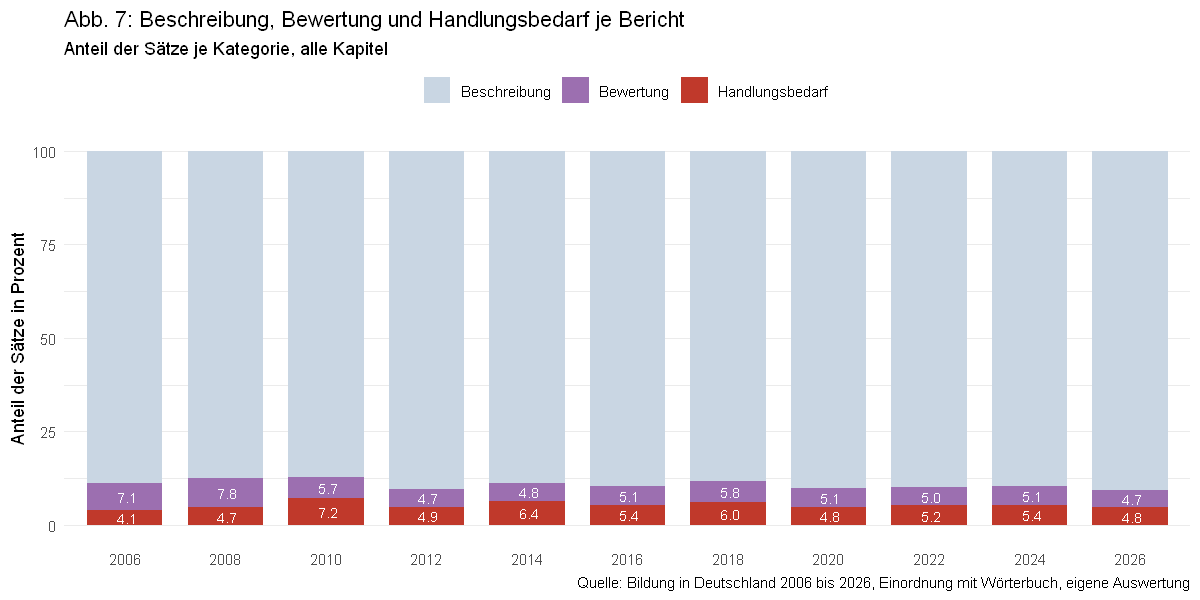

In [5]:
options(repr.plot.width = 10, repr.plot.height = 5)

farben_kategorie <- c("Beschreibung" = "#c9d6e3", "Bewertung" = "#9c6fb0", "Handlungsbedarf" = "#c0392b")
farben_kapitel <- c("Kernkapitel" = "#9e9e9e", "Schwerpunkt H" = "#e07b39",
                    "Überblick" = "#1f4e79", "Einleitung" = "#c9d6e3")
quelle <- "Quelle: Bildung in Deutschland 2006 bis 2026, Einordnung mit Wörterbuch, eigene Auswertung"

anteile_jahr <- saetze |>
  count(jahr, kategorie) |>
  group_by(jahr) |>
  mutate(anteil = 100 * n / sum(n)) |>
  ungroup()

abb7 <- ggplot(anteile_jahr, aes(factor(jahr), anteil, fill = kategorie)) +
  geom_col(width = 0.75) +
  geom_text(aes(label = ifelse(kategorie == "Beschreibung", "", format(round(anteil, 1), nsmall = 1))),
            position = position_stack(vjust = 0.5), size = 3, colour = "white") +
  scale_fill_manual(values = farben_kategorie, name = NULL) +
  labs(x = NULL, y = "Anteil der Sätze in Prozent",
       title = "Abb. 7: Beschreibung, Bewertung und Handlungsbedarf je Bericht",
       subtitle = "Anteil der Sätze je Kategorie, alle Kapitel",
       caption = quelle) +
  theme_minimal(base_size = 11) +
  theme(legend.position = "top", panel.grid.major.x = element_blank())

ggsave("figures/abb7_kategorien_jahr.png", abb7, width = 10, height = 5, dpi = 300, bg = "white")
abb7

anteile_jahr |>
  mutate(anteil = round(anteil, 1)) |>
  select(-n) |>
  pivot_wider(names_from = kategorie, values_from = anteil)

**Befund zu Abbildung 7:** Die Verteilung der drei Kategorien bleibt über 20 Jahre nahezu gleich. Rund 87 bis 91 Prozent der Sätze beschreiben. Der Anteil der Bewertung liegt zwischen 4,7 und 7,8 Prozent, der Anteil des Handlungsbedarfs zwischen 4,1 und 7,2 Prozent. Einen Trend zeigt keine der beiden Kategorien.

Zwei kleine Verschiebungen fallen auf: Die Berichte 2006 und 2008 bewerten etwas häufiger (7,1 und 7,8 Prozent) als alle späteren (4,7 bis 5,8 Prozent). Der Handlungsbedarf erreicht seine höchsten Werte 2010 (7,2 Prozent) und 2014 (6,4 Prozent). Abbildung 8 zeigt, dass beide Spitzen aus dem Schwerpunktkapitel stammen.

Für Forschungsfrage 3 heißt das: Der Bildungsbericht bleibt über 20 Jahre ein beschreibender Bericht. Er wird weder wertender noch fordernder.

#### Abbildung 8: Bewertung und Handlungsbedarf nach Kapitelgruppe

Das linke Feld zeigt den Anteil der bewertenden Sätze, das rechte den Anteil der Sätze mit Handlungsbedarf. Jede Linie ist eine Kapitelgruppe. Die Einleitung lasse ich weg, weil sie je Bericht nur 12 bis 34 Absätze umfasst.

So liest man die Abbildung: Liegt die blaue Linie (Überblick) deutlich über der grauen (Kernkapitel), konzentriert der Bericht Bewertung oder Handlungsbedarf in der Zusammenfassung. Steigt die graue Linie, verändert sich die Sprache in den fortgeschriebenen Kapiteln selbst.

kapitelgruppe,kategorie,2006,2008,2010,2012,2014,2016,2018,2020,2022,2024,2026
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Kernkapitel,Bewertung,5.6,7.4,6.3,4.7,5.1,4.8,5.0,4.2,5.2,4.1,4.7
Schwerpunkt H,Bewertung,9.8,8.6,4.4,3.1,3.0,5.5,7.9,6.7,4.3,7.3,3.9
Überblick,Bewertung,13.4,10.2,3.1,10.8,8.1,6.6,5.5,6.6,5.1,7.1,5.7
Kernkapitel,Handlungsbedarf,3.5,4.3,4.2,4.2,4.7,3.9,5.1,3.5,3.8,3.9,3.7
Schwerpunkt H,Handlungsbedarf,4.9,4.9,16.3,4.5,10.2,6.7,5.1,7.9,7.9,7.1,5.2
Überblick,Handlungsbedarf,5.9,7.9,8.2,11.8,12.1,13.2,12.4,6.3,7.0,10.7,8.5


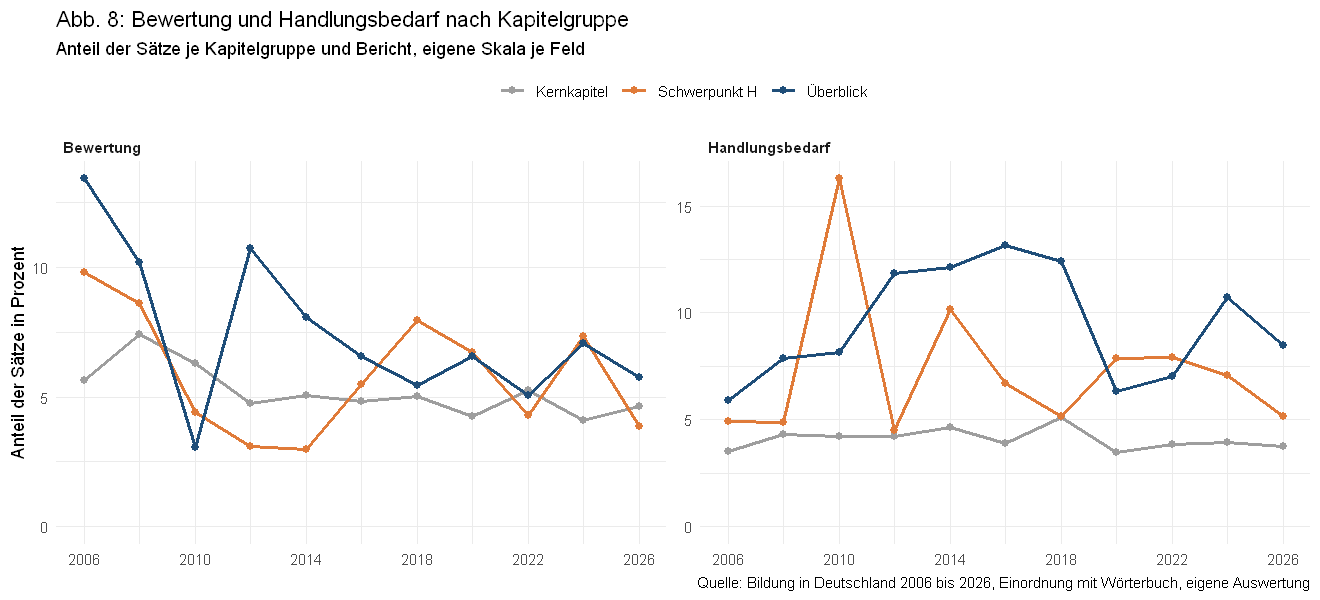

In [6]:
options(repr.plot.width = 11, repr.plot.height = 5)

anteile_gruppe <- saetze |>
  filter(kapitelgruppe != "Einleitung") |>
  group_by(jahr, kapitelgruppe) |>
  summarise(saetze = n(),
            Bewertung = 100 * mean(kategorie == "Bewertung"),
            Handlungsbedarf = 100 * mean(kategorie == "Handlungsbedarf"),
            .groups = "drop") |>
  pivot_longer(c(Bewertung, Handlungsbedarf), names_to = "kategorie", values_to = "anteil")

abb8 <- ggplot(anteile_gruppe, aes(jahr, anteil, colour = kapitelgruppe)) +
  geom_line(linewidth = 1) +
  geom_point(size = 2) +
  facet_wrap(~ kategorie, scales = "free_y") +
  scale_colour_manual(values = farben_kapitel, name = NULL,
                      breaks = c("Kernkapitel", "Schwerpunkt H", "Überblick")) +
  scale_x_continuous(breaks = seq(2006, 2026, 4)) +
  expand_limits(y = 0) +
  labs(x = NULL, y = "Anteil der Sätze in Prozent",
       title = "Abb. 8: Bewertung und Handlungsbedarf nach Kapitelgruppe",
       subtitle = "Anteil der Sätze je Kapitelgruppe und Bericht, eigene Skala je Feld",
       caption = quelle) +
  theme_minimal(base_size = 11) +
  theme(legend.position = "top", strip.text = element_text(face = "bold", hjust = 0))

ggsave("figures/abb8_kategorien_kapitelgruppe.png", abb8, width = 11, height = 5, dpi = 300, bg = "white")
abb8

anteile_gruppe |>
  mutate(anteil = round(anteil, 1)) |>
  select(-saetze) |>
  pivot_wider(names_from = jahr, values_from = anteil) |>
  arrange(kategorie, kapitelgruppe)

**Befund zu Abbildung 8:** Die Kapitelgruppen unterscheiden sich deutlich.

- In den Kernkapiteln bleibt die Sprache über 20 Jahre stabil: Handlungsbedarf zwischen 3,5 und 5,1 Prozent, Bewertung zwischen 4,1 und 7,4 Prozent.
- Im Überblick steigt der Handlungsbedarf von 5,9 Prozent (2006) auf 11,8 bis 13,2 Prozent in den Berichten 2012 bis 2018. 2020 fällt er auf 6,3 Prozent und liegt danach zwischen 7,0 und 10,7 Prozent.
- Im Schwerpunktkapitel schwankt der Handlungsbedarf mit dem Thema. Die Spitzen liegen 2010 (16,3 Prozent, demografischer Wandel) und 2014 (10,2 Prozent, Menschen mit Behinderungen).
- Die Bewertung ist in den ersten Berichten im Überblick (13,4 Prozent 2006) und im Schwerpunktkapitel (9,8 Prozent 2006) am höchsten und sinkt danach.

Der Teil "Zentrale Herausforderungen" im Überblick 2026 erhöht den Anteil des Handlungsbedarfs nicht (8,5 Prozent). Der Überblick 2026 ist mit 731 Sätzen rund 40 Prozent länger als 2022. Der neue Teil verteilt sich also auf einen deutlich größeren Text.

Der Bericht trennt also Darstellung und Einordnung: Die Kernkapitel beschreiben, Überblick und Schwerpunktkapitel benennen den Handlungsbedarf.

#### Abbildung 9: Handlungsbedarf nach Kapitel

Die Heatmap zeigt für jedes Kapitel und jeden Bericht den Anteil der Sätze mit Handlungsbedarf. Je dunkler das Feld, desto höher der Anteil. Ein leeres Feld bedeutet, dass das Kapitel in diesem Bericht fehlt (Kapitel I im Jahr 2018).

Die Kapitel stehen in der Reihenfolge des Berichts: Einleitung, Kapitel A bis I mit dem Schwerpunktkapitel H, am Ende der Überblick.

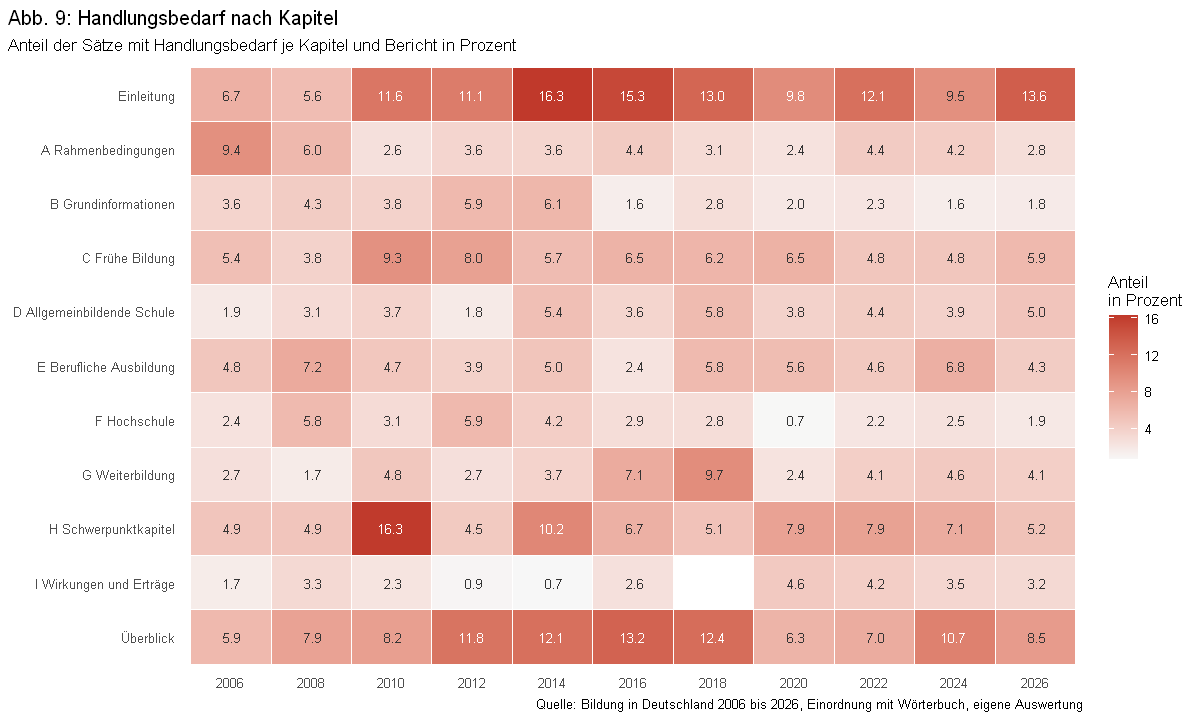

In [7]:
options(repr.plot.width = 10, repr.plot.height = 6)

reihenfolge_kapitel <- c("EIN", "A", "B", "C", "D", "E", "F", "G", "H", "I", "UEB")
namen_kapitel <- c("EIN" = "Einleitung", "A" = "A Rahmenbedingungen", "B" = "B Grundinformationen",
                   "C" = "C Frühe Bildung", "D" = "D Allgemeinbildende Schule",
                   "E" = "E Berufliche Ausbildung", "F" = "F Hochschule", "G" = "G Weiterbildung",
                   "H" = "H Schwerpunktkapitel", "I" = "I Wirkungen und Erträge", "UEB" = "Überblick")

anteile_kapitel <- saetze |>
  group_by(jahr, kapitel) |>
  summarise(saetze = n(), anteil = 100 * mean(kategorie == "Handlungsbedarf"), .groups = "drop") |>
  mutate(kapitel_name = factor(namen_kapitel[kapitel], levels = rev(namen_kapitel[reihenfolge_kapitel])))

abb9 <- ggplot(anteile_kapitel, aes(factor(jahr), kapitel_name, fill = anteil)) +
  geom_tile(colour = "white", linewidth = 0.4) +
  geom_text(aes(label = format(round(anteil, 1), nsmall = 1),
                colour = anteil > 0.6 * max(anteil)), size = 2.8, show.legend = FALSE) +
  scale_fill_gradient(low = "#f7f7f7", high = "#c0392b", name = "Anteil\nin Prozent") +
  scale_colour_manual(values = c("FALSE" = "grey20", "TRUE" = "white")) +
  labs(x = NULL, y = NULL,
       title = "Abb. 9: Handlungsbedarf nach Kapitel",
       subtitle = "Anteil der Sätze mit Handlungsbedarf je Kapitel und Bericht in Prozent",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(panel.grid = element_blank(), plot.title.position = "plot")

ggsave("figures/abb9_handlungsbedarf_kapitel.png", abb9, width = 10, height = 6, dpi = 300, bg = "white")
abb9

write.csv(anteile_kapitel |> select(-kapitel_name), "data/processed/handlungsbedarf_kapitel_jahr.csv",
          row.names = FALSE, fileEncoding = "UTF-8")

**Befund zu Abbildung 9:** Den höchsten Anteil an Handlungsbedarf haben die Einleitung (5,6 bis 16,3 Prozent) und der Überblick (5,9 bis 13,2 Prozent). Unter den Kernkapiteln liegt Kapitel C zur frühen Bildung am höchsten (3,8 bis 9,3 Prozent, Spitze 2010). Am niedrigsten liegen Kapitel B mit den Grundinformationen (seit 2016 höchstens 2,8 Prozent) und Kapitel F zur Hochschule (0,7 bis 5,9 Prozent). Kapitel I zu Wirkungen und Erträgen benennt bis 2016 kaum Handlungsbedarf (0,7 bis 3,3 Prozent), seit 2020 etwas mehr (3,2 bis 4,6 Prozent). Kapitel A hat 2006 mit 9,4 Prozent einen Ausreißer.

### 5. Handlungsbedarf nach Thema

Dieser Abschnitt beantwortet den ersten Teil von Forschungsfrage 2: Zu welchen Themen benennt der Bericht wiederholt Handlungsbedarf?

Jeder Satz erhält das Hauptthema seines Absatzes. Das Hauptthema ist das inhaltliche Thema mit dem höchsten Anteil im Absatz, berechnet aus dem Modell mit 40 Themen. Die 8 Themen der Berichtssprache zählen dabei nicht mit, es bleiben 32 inhaltliche Themen. Ein Absatz über Kindertagesbetreuung, der mit "Hier besteht weiterhin Handlungsbedarf" endet, ordnet diesen Handlungsbedarf also dem Thema Kindertagesbetreuung zu.

Die Zuordnung über den Absatz setzt voraus, dass die Zeilen des Modells und die Absätze übereinstimmen. Die erste Zelle prüft das: Für jeden Absatz im Modell muss das Jahr in `stm_daten.rds` mit dem Jahr in `dokumente.rds` übereinstimmen. 63 der 9.188 Absätze fehlen im Modell, weil sie nach der Bereinigung weniger als fünf Wörter hatten. Ihre Sätze fallen hier weg.

Ein Bericht zählt für ein Thema, wenn zwei Bedingungen erfüllt sind:

1. Der Bericht enthält mindestens 3 Sätze mit Handlungsbedarf zu diesem Thema. Ein einzelner Satz zählt also nicht.
2. Die Quote des Themas in diesem Bericht liegt über der Quote des ganzen Berichts. Das Thema erhält also überdurchschnittlich oft Handlungsbedarf.

Als wiederkehrend gilt ein Thema, wenn mindestens 6 der 11 Berichte für es zählen, also mehr als die Hälfte.

Die zweite Bedingung kam nach dem ersten Lauf hinzu. Mit der ersten Bedingung allein galten 23 von 32 Themen als wiederkehrend. Große Themen erreichen 3 Sätze schon, weil der Bericht viel über sie schreibt, besonders in den längeren Berichten ab 2020. Die Regel trennte dann kaum zwischen Themen. Der Vergleich mit der Quote des Berichts gleicht Umfang und Länge aus.

Ich gebe zwei Kennzahlen aus:

- Berichte: in wie vielen Berichten das Thema nach beiden Bedingungen zählt, einmal über alle Kapitel, einmal nur in den Kernkapiteln.
- Quote: welcher Anteil der Sätze eines Themas Handlungsbedarf benennt. Die Quote zeigt, bei welchen Themen der Bericht eher fordert als beschreibt, unabhängig davon, wie viel er über das Thema schreibt.

Die Tabelle speichere ich unter `data/processed/handlungsbedarf_themen.csv`, die Zahl der Sätze mit Handlungsbedarf je Thema und Jahr unter `data/processed/handlungsbedarf_themen_jahr.csv`. `05_indikatoren.ipynb` nutzt die zweite Datei für den Abgleich mit den Indikatoren.

In [8]:
stm_daten <- readRDS("data/interim/stm_daten.rds")
modell_k40 <- readRDS("data/interim/stm_k40.rds")
themen_namen <- read.csv("data/processed/stm_themen_k40_namen.csv", fileEncoding = "UTF-8")

absatz_modell <- as.integer(names(stm_daten$documents))
stopifnot("Die Dokumente in stm_daten.rds tragen keine Absatznummern." = length(absatz_modell) > 0)
jahr_dokumente <- dokumente$jahr[match(absatz_modell, dokumente$absatz_id)]
cat("Absätze im Modell:", length(absatz_modell), "\n")
cat("Jahr stimmt für alle Absätze überein:", identical(as.numeric(jahr_dokumente),
                                                      as.numeric(stm_daten$meta$jahr)), "\n")
stopifnot(identical(as.numeric(jahr_dokumente), as.numeric(stm_daten$meta$jahr)))

inhalt <- themen_namen |>
  filter(gruppe != "Berichtssprache") |>
  arrange(thema)
theta_inhalt <- modell_k40$theta[, inhalt$thema]
hauptthema <- tibble(absatz_id = absatz_modell,
                     thema = inhalt$thema[max.col(theta_inhalt, ties.method = "first")])

saetze_thema <- saetze |>
  inner_join(hauptthema, by = "absatz_id") |>
  left_join(inhalt |> select(thema, kurzname, gruppe), by = "thema") |>
  mutate(label = paste0("T", thema, " ", kurzname))
cat("Sätze mit Hauptthema:", nrow(saetze_thema), "von", nrow(saetze), "\n\n")

min_saetze <- 3
min_berichte <- 6

# Ein Bericht zählt für ein Thema: mindestens n_min Sätze mit Handlungsbedarf
# und eine Quote über der Quote des ganzen Berichts
zaehle_berichte <- function(daten, spalte, n_min = min_saetze) {
  daten |>
    group_by(jahr) |>
    mutate(quote_bericht = mean({{ spalte }})) |>
    group_by(thema, jahr) |>
    summarise(n_h = sum({{ spalte }}),
              quote = mean({{ spalte }}),
              quote_bericht = first(quote_bericht),
              .groups = "drop") |>
    group_by(thema) |>
    summarise(berichte = sum(n_h >= n_min & quote > quote_bericht), .groups = "drop")
}

saetze_thema <- saetze_thema |>
  mutate(ist_h = kategorie == "Handlungsbedarf")
kern <- saetze_thema |> filter(kapitelgruppe == "Kernkapitel")

themen_h <- saetze_thema |>
  group_by(thema, label, kurzname, gruppe) |>
  summarise(saetze = n(),
            handlungsbedarf = sum(ist_h),
            quote = round(100 * handlungsbedarf / saetze, 1),
            .groups = "drop") |>
  left_join(zaehle_berichte(saetze_thema, ist_h), by = "thema") |>
  left_join(zaehle_berichte(kern, ist_h) |> rename(berichte_kern = berichte), by = "thema") |>
  mutate(across(c(berichte, berichte_kern), \(x) coalesce(x, 0L)),
         wiederkehrend = berichte >= min_berichte) |>
  arrange(desc(berichte), desc(handlungsbedarf))

h_jahr <- saetze_thema |>
  filter(ist_h) |>
  count(thema, label, jahr, name = "handlungsbedarf") |>
  complete(nesting(thema, label), jahr = sort(unique(saetze$jahr)), fill = list(handlungsbedarf = 0))

write.csv(themen_h, "data/processed/handlungsbedarf_themen.csv", row.names = FALSE, fileEncoding = "UTF-8")
write.csv(h_jahr, "data/processed/handlungsbedarf_themen_jahr.csv", row.names = FALSE, fileEncoding = "UTF-8")

cat("Wiederkehrende Themen (mindestens", min_saetze, "Sätze und überdurchschnittliche Quote in mindestens",
    min_berichte, "Berichten):",
    sum(themen_h$wiederkehrend), "von", nrow(themen_h), "\n\n")
print(themen_h |> select(thema, kurzname, saetze, handlungsbedarf, quote, berichte, berichte_kern, wiederkehrend),
      n = 32, width = Inf)

Absätze im Modell: 9125 
Jahr stimmt für alle Absätze überein: TRUE 
Sätze mit Hauptthema: 41251 von 41314 

Wiederkehrende Themen (mindestens 3 Sätze und überdurchschnittliche Quote in mindestens 6 Berichten): 9 von 32 

# A tibble: 32 × 8
   thema kurzname                                   saetze handlungsbedarf quote
   <int> <chr>                                       <int>           <int> <dbl>
 1     5 Steuerung des Bildungssystems                1253             251  20  
 2    33 Programme und Qualitätssicherung             1305             146  11.2
 3    12 Demografischer und wirtschaftlicher Wandel   1220             140  11.5
 4     3 Frühe Bildung allgemein                       665              56   8.4
 5    18 Ausbildungsmarkt und Übergangssystem         1575              98   6.2
 6    30 Kindertagesbetreuung                         2328             150   6.4
 7    11 Pädagogisches Personal                       1830             134   7.3
 8    38 Soziale Herkunft und 

**Befund zu Abschnitt 5:** Die Zuordnung zum Modell stimmt: Für alle 9.125 Absätze im Modell stimmt das Jahr überein. 41.251 der 41.314 Sätze erhalten ein Hauptthema.

Nach der Regel aus beiden Bedingungen gelten 9 von 32 Themen als wiederkehrend:

| Thema | Sätze mit Handlungsbedarf | Quote in Prozent | Berichte |
|---|---|---|---|
| T5 Steuerung des Bildungssystems | 251 | 20,0 | 11 |
| T33 Programme und Qualitätssicherung | 146 | 11,2 | 9 |
| T12 Demografischer und wirtschaftlicher Wandel | 140 | 11,5 | 9 |
| T3 Frühe Bildung allgemein | 56 | 8,4 | 8 |
| T18 Ausbildungsmarkt und Übergangssystem | 98 | 6,2 | 7 |
| T30 Kindertagesbetreuung | 150 | 6,4 | 6 |
| T11 Pädagogisches Personal | 134 | 7,3 | 6 |
| T38 Soziale Herkunft und Ungleichheit | 78 | 4,9 | 6 |
| T29 Lehrkräfte | 56 | 6,3 | 6 |

Am anderen Ende stehen große Themen, die der Bericht fast nur als Kennzahl fortschreibt: Bildungsstand der Bevölkerung (Quote 1,8 Prozent), Studienberechtigung und Hochschulabschluss (1,9), Bildungsausgaben (2,5) und internationaler Vergleich (2,9). Sie zählen in keinem oder höchstens einem Bericht.

Steuerung (T5) zählt in allen 11 Berichten, in den Kernkapiteln aber nur in 3. Der Handlungsbedarf zur Steuerung steht also fast nur in Überblick, Einleitung und Schwerpunktkapiteln. Abschnitt 6 prüft, ob dieser Befund am Wort "Herausforderung" hängt.

#### Abbildung 10: Handlungsbedarf nach Thema und Bericht

Jede Zeile ist ein inhaltliches Thema, jede Spalte ein Bericht. Die Zahl im Feld ist die Zahl der Sätze mit Handlungsbedarf zu diesem Thema. Das obere Feld zeigt die wiederkehrenden Themen, das untere die übrigen. Innerhalb jedes Felds stehen die Themen nach der Zahl der Berichte sortiert.

So liest man die Abbildung: Eine durchgehend gefärbte Zeile ist eine Herausforderung, die der Bericht über 20 Jahre immer wieder benennt. Ein einzelnes dunkles Feld ist eine Herausforderung, die nur ein Bericht hervorhebt, meist im Schwerpunktkapitel. Die Berichte ab 2020 sind länger (Abbildung 1). Höhere Zahlen in diesen Jahren gehen deshalb zum Teil auf den Umfang zurück.

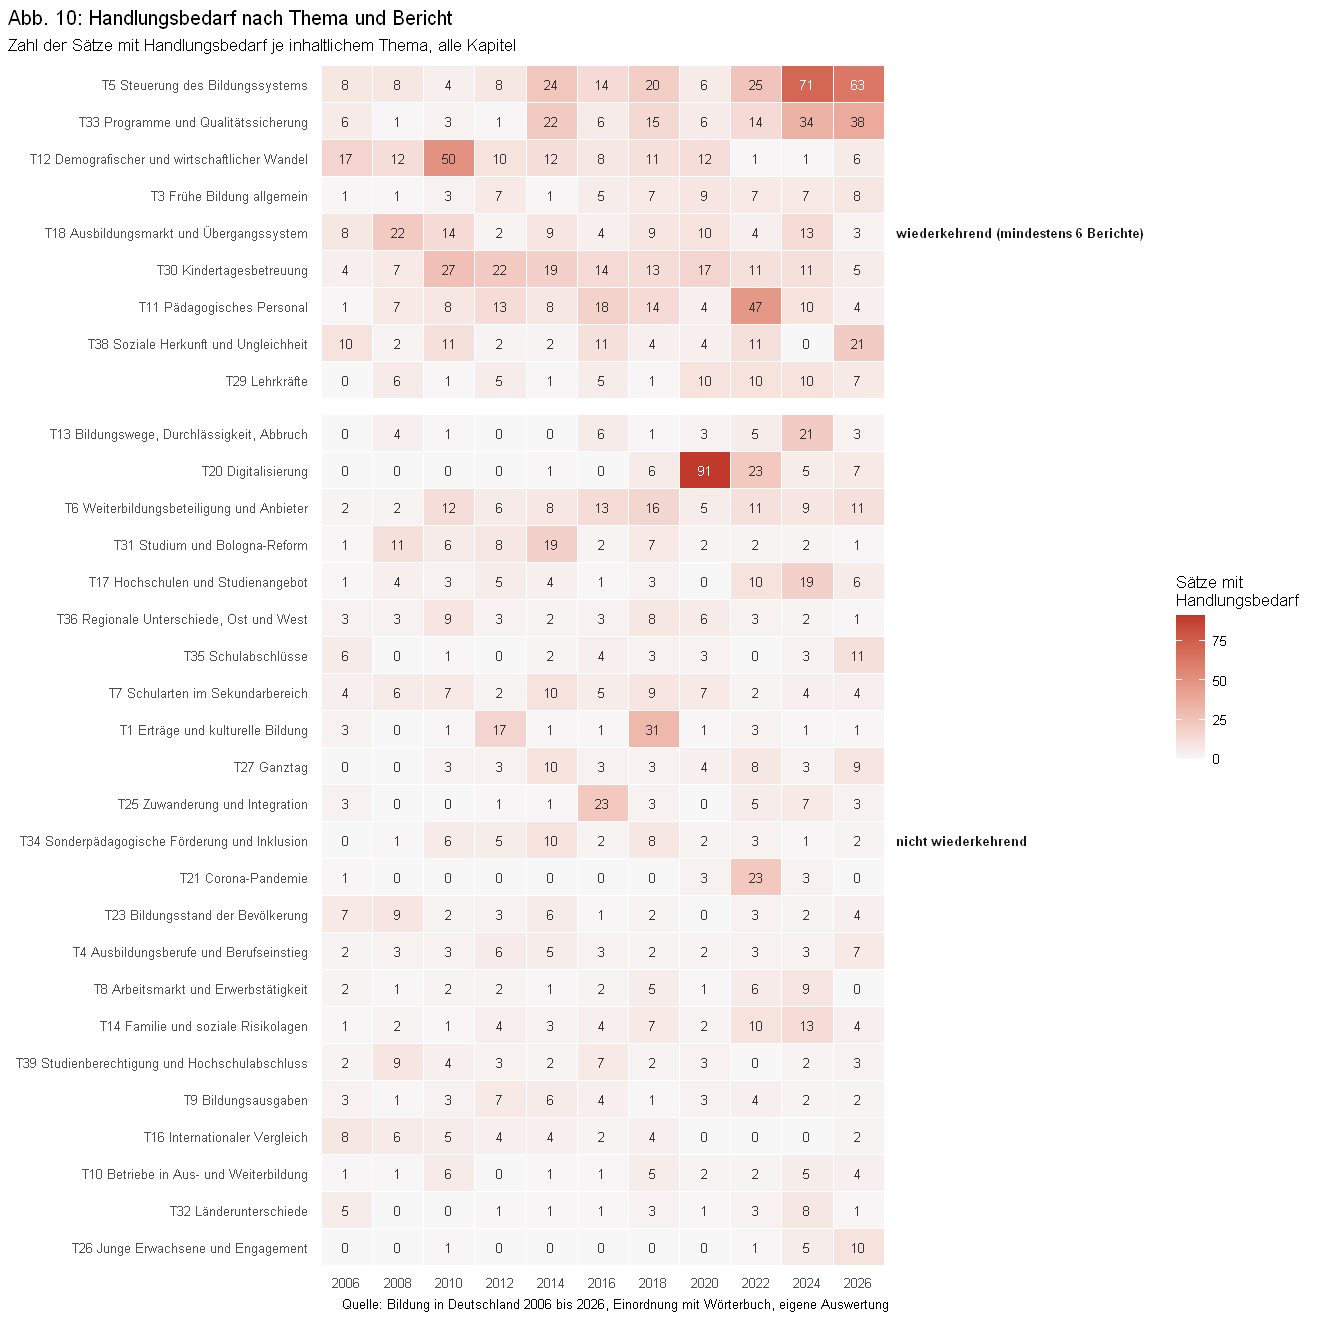

In [9]:
options(repr.plot.width = 11, repr.plot.height = 11)

reihenfolge_themen <- themen_h |> arrange(berichte, handlungsbedarf) |> pull(label)
abb10_daten <- h_jahr |>
  left_join(themen_h |> select(thema, wiederkehrend), by = "thema") |>
  mutate(label = factor(label, levels = reihenfolge_themen),
         feld = factor(ifelse(wiederkehrend,
                              paste0("wiederkehrend (mindestens ", min_berichte, " Berichte)"),
                              "nicht wiederkehrend"),
                       levels = c(paste0("wiederkehrend (mindestens ", min_berichte, " Berichte)"),
                                  "nicht wiederkehrend")))

abb10 <- ggplot(abb10_daten, aes(factor(jahr), label, fill = handlungsbedarf)) +
  geom_tile(colour = "white", linewidth = 0.4) +
  geom_text(aes(label = handlungsbedarf,
                colour = handlungsbedarf > 0.6 * max(handlungsbedarf)), size = 2.7, show.legend = FALSE) +
  facet_grid(feld ~ ., scales = "free_y", space = "free_y") +
  scale_fill_gradient(low = "#f7f7f7", high = "#c0392b", name = "Sätze mit\nHandlungsbedarf") +
  scale_colour_manual(values = c("FALSE" = "grey20", "TRUE" = "white")) +
  labs(x = NULL, y = NULL,
       title = "Abb. 10: Handlungsbedarf nach Thema und Bericht",
       subtitle = "Zahl der Sätze mit Handlungsbedarf je inhaltlichem Thema, alle Kapitel",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(panel.grid = element_blank(), plot.title.position = "plot",
        strip.text.y = element_text(angle = 0, face = "bold", hjust = 0))

ggsave("figures/abb10_handlungsbedarf_themen.png", abb10, width = 11, height = 11, dpi = 300, bg = "white")
abb10

**Befund zu Abbildung 10:** Die Abbildung zeigt drei Verläufe.

1. **Zunehmende Herausforderungen.** Steuerung (T5) liegt bis 2012 bei 4 bis 8 Sätzen je Bericht und steigt 2024 auf 71 und 2026 auf 63. Programme und Qualitätssicherung (T33) steigen auf 34 (2024) und 38 Sätze (2026). Lehrkräfte (T29) liegen seit 2020 bei 7 bis 10 Sätzen, vorher meist darunter.
2. **Abnehmende Herausforderungen.** Der demografische Wandel (T12) erreicht 2010 mit 50 Sätzen den Höchstwert, im Jahr des gleichnamigen Schwerpunkts, und fällt 2022 und 2024 auf je einen Satz. Kindertagesbetreuung (T30) liegt 2010 bis 2014 bei 19 bis 27 Sätzen, in den Jahren des Krippenausbaus, und sinkt bis 2026 auf 5.
3. **Einmalige Spitzen aus Schwerpunkten und Ereignissen.** Digitalisierung 2020 (91 Sätze), pädagogisches Personal 2022 (47), Zuwanderung 2016 (23), Corona 2022 (23), Bildungswege und Abbruch 2024 (21), Erträge und kulturelle Bildung 2012 und 2018 (17 und 31). Diese Themen gelten nicht als wiederkehrend, weil der Handlungsbedarf an einen Bericht gebunden ist.

Soziale Herkunft (T38) erhält über 20 Jahre in fast jedem Bericht Handlungsbedarf, mit 21 Sätzen 2026 am meisten. Die Berichte ab 2020 sind länger, die Zählungen dieser Jahre sind deshalb nur eingeschränkt mit den frühen Berichten vergleichbar.

#### Abbildung 11: Quote des Handlungsbedarfs nach Thema

Jeder Balken zeigt, welcher Anteil der Sätze eines Themas Handlungsbedarf benennt. Die Zahl am Balken ist die Zahl der Berichte, die nach den Bedingungen aus Abschnitt 5 für das Thema zählen. Rote Balken markieren die wiederkehrenden Themen.

So liest man die Abbildung: Ein Thema mit hoher Quote behandelt der Bericht eher fordernd als beschreibend. Ein Thema mit niedriger Quote schreibt er vor allem als Kennzahl fort. Hohe Quote und viele Berichte zusammen kennzeichnen die zentralen, wiederkehrenden Herausforderungen.

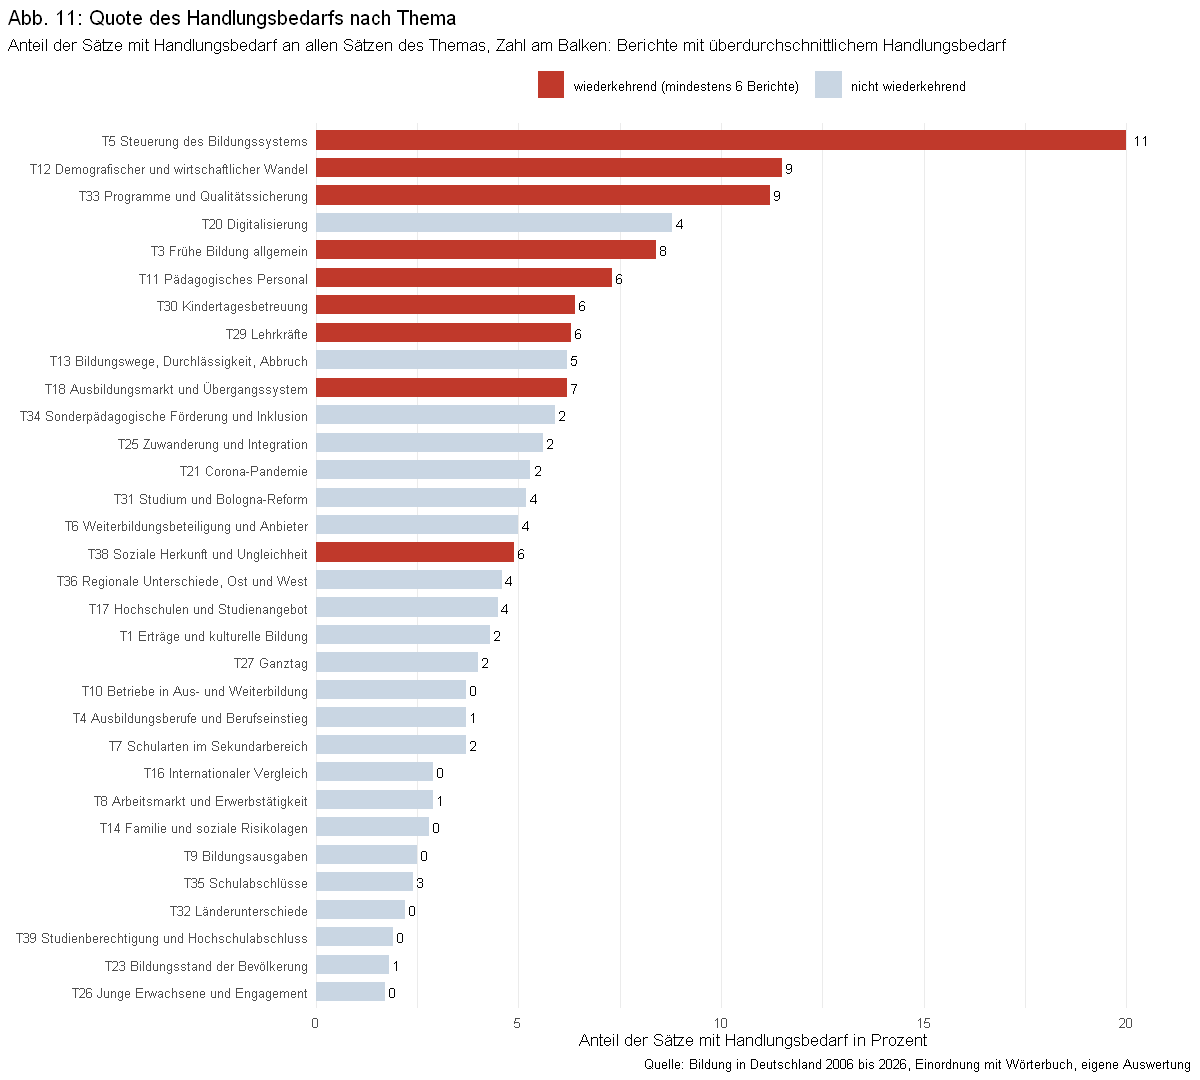

In [10]:
options(repr.plot.width = 10, repr.plot.height = 9)

abb11_daten <- themen_h |>
  arrange(quote) |>
  mutate(label = factor(label, levels = label))

abb11 <- ggplot(abb11_daten, aes(quote, label, fill = wiederkehrend)) +
  geom_col(width = 0.7) +
  geom_text(aes(label = berichte), hjust = -0.4, size = 3) +
  scale_fill_manual(values = c("TRUE" = "#c0392b", "FALSE" = "#c9d6e3"),
                    labels = c("TRUE" = paste0("wiederkehrend (mindestens ", min_berichte, " Berichte)"),
                               "FALSE" = "nicht wiederkehrend"),
                    breaks = c("TRUE", "FALSE"), name = NULL) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.08))) +
  labs(x = "Anteil der Sätze mit Handlungsbedarf in Prozent", y = NULL,
       title = "Abb. 11: Quote des Handlungsbedarfs nach Thema",
       subtitle = "Anteil der Sätze mit Handlungsbedarf an allen Sätzen des Themas, Zahl am Balken: Berichte mit überdurchschnittlichem Handlungsbedarf",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(legend.position = "top", plot.title.position = "plot",
        panel.grid.major.y = element_blank())

ggsave("figures/abb11_quote_handlungsbedarf.png", abb11, width = 10, height = 9, dpi = 300, bg = "white")
abb11

**Befund zu Abbildung 11:** Steuerung (T5) hat mit 20,0 Prozent die mit Abstand höchste Quote. Jeder fünfte Satz zu diesem Thema benennt Handlungsbedarf. Es folgen demografischer Wandel (11,5), Programme und Qualitätssicherung (11,2), Digitalisierung (8,8) und frühe Bildung (8,4). Digitalisierung hat eine hohe Quote, gilt aber nicht als wiederkehrend, weil der Handlungsbedarf vor allem im Schwerpunkt 2020 steht.

Die niedrigsten Quoten haben junge Erwachsene und Engagement (1,7), Bildungsstand der Bevölkerung (1,8) und Studienberechtigung (1,9). Sieben Themen zählen in keinem Bericht.

Die Abbildung trennt zwei Gruppen von Themen: Themen, bei denen der Bericht über Aufgaben und Handlungsbedarf spricht, und Themen, die er als Kennzahl fortschreibt, ohne daraus Forderungen abzuleiten.

### 6. Robustheit

Die Einordnung hängt an drei Entscheidungen, die ich hier prüfe:

1. **Modalverben.** Die Liste für Handlungsbedarf enthält "müssen", "sollte" und "erforderlich". Diese Wörter treten auch in beschreibenden Sätzen auf. Ich wiederhole die Auswertung aus Abschnitt 5 mit der strengen Liste aus Abschnitt 2, die nur ausdrückliche Wendungen wie "Herausforderung" oder "Handlungsbedarf" enthält.
2. **Kapitel.** Schwerpunktkapitel und Überblick können ein Thema in einzelnen Berichten hervorheben. Die Spalte `berichte_kern` aus Abschnitt 5 zählt nur die Kernkapitel.
3. **Zirkelschluss bei Steuerung.** Das Wort "Herausforderung" ist das zweithäufigste Wort von Thema 5 (Steuerung des Bildungssystems, Abschnitt 8 in `02_stm_modell.ipynb`). Absätze mit "Herausforderung" ziehen das Modell also zu Thema 5, und dieselben Sätze zählen hier als Handlungsbedarf. Das kann Thema 5 künstlich nach vorne bringen. Zur Prüfung ordne ich jeden Absatz noch einmal seinem Hauptthema zu, diesmal ohne Thema 5. Absätze von Thema 5 erhalten dann ihr zweitstärkstes inhaltliches Thema.

Als robust gilt ein wiederkehrendes Thema, wenn es auch mit der strengen Liste in mindestens 6 Berichten zählt. Mit der strengen Liste gibt es weniger Treffer. Ich senke deshalb die Mindestzahl je Bericht auf einen Satz, die Bedingung zur Quote bleibt. Zusätzlich vergleiche ich die Rangfolge der Themen beider Listen mit der Rangkorrelation nach Spearman: Ein Wert nahe 1 heißt, dass beide Listen dieselben Themen vorne sehen.

In [11]:
streng_berichte <- zaehle_berichte(saetze_thema, handlung_streng, n_min = 1) |>
  rename(berichte_streng = berichte) |>
  left_join(saetze_thema |> group_by(thema) |>
              summarise(handlungsbedarf_streng = sum(handlung_streng)), by = "thema")

robust <- themen_h |>
  left_join(streng_berichte, by = "thema") |>
  mutate(across(c(berichte_streng, handlungsbedarf_streng), \(x) coalesce(x, 0L)),
         wiederkehrend_streng = berichte_streng >= min_berichte,
         wiederkehrend_kern = berichte_kern >= min_berichte,
         robust = wiederkehrend & wiederkehrend_streng)

rang <- cor(robust$handlungsbedarf, robust$handlungsbedarf_streng, method = "spearman")
cat("Rangkorrelation der Themen, Wörterbuch und strenge Liste:", round(rang, 2), "\n\n")
cat("Wiederkehrend mit dem Wörterbuch:", sum(robust$wiederkehrend), "\n")
cat("Wiederkehrend mit der strengen Liste:", sum(robust$wiederkehrend_streng), "\n")
cat("Wiederkehrend nur in den Kernkapiteln:", sum(robust$wiederkehrend_kern), "\n")
cat("Robust (Wörterbuch und strenge Liste):", sum(robust$robust), "\n\n")

print(robust |>
        select(thema, kurzname, berichte, berichte_kern, berichte_streng,
               handlungsbedarf, handlungsbedarf_streng, wiederkehrend, robust),
      n = 32, width = Inf)

write.csv(robust, "data/processed/handlungsbedarf_themen.csv", row.names = FALSE, fileEncoding = "UTF-8")

# Prüfung 3: Hauptthema ohne Thema 5
ohne_t5 <- inhalt$thema != 5
hauptthema_ohne5 <- tibble(absatz_id = absatz_modell,
                           thema = inhalt$thema[ohne_t5][max.col(theta_inhalt[, ohne_t5], ties.method = "first")])
saetze_ohne5 <- saetze |>
  inner_join(hauptthema_ohne5, by = "absatz_id") |>
  mutate(ist_h = kategorie == "Handlungsbedarf")
vergleich_t5 <- saetze_ohne5 |>
  group_by(thema) |>
  summarise(handlungsbedarf_ohne5 = sum(ist_h), .groups = "drop") |>
  left_join(zaehle_berichte(saetze_ohne5, ist_h) |> rename(berichte_ohne5 = berichte), by = "thema") |>
  left_join(themen_h |> select(thema, kurzname, handlungsbedarf, berichte), by = "thema") |>
  mutate(zuwachs = handlungsbedarf_ohne5 - handlungsbedarf,
         berichte_ohne5 = coalesce(berichte_ohne5, 0L)) |>
  arrange(desc(zuwachs))

cat("\nSätze mit Handlungsbedarf bei Thema 5:", themen_h$handlungsbedarf[themen_h$thema == 5], "\n")
cat("Wohin sie ohne Thema 5 gehen (Themen mit dem größten Zuwachs):\n")
print(vergleich_t5 |> filter(zuwachs > 0) |>
        select(thema, kurzname, handlungsbedarf, handlungsbedarf_ohne5, zuwachs, berichte, berichte_ohne5),
      n = 10, width = Inf)
cat("\nWiederkehrend ohne Thema 5:", sum(vergleich_t5$berichte_ohne5 >= min_berichte), "Themen\n")

Rangkorrelation der Themen, Wörterbuch und strenge Liste: 0.87 

Wiederkehrend mit dem Wörterbuch: 9 
Wiederkehrend mit der strengen Liste: 9 
Wiederkehrend nur in den Kernkapiteln: 6 
Robust (Wörterbuch und strenge Liste): 8 

# A tibble: 32 × 9
   thema kurzname                                   berichte berichte_kern
   <int> <chr>                                         <int>         <int>
 1     5 Steuerung des Bildungssystems                    11             3
 2    33 Programme und Qualitätssicherung                  9             5
 3    12 Demografischer und wirtschaftlicher Wandel        9             9
 4     3 Frühe Bildung allgemein                           8             7
 5    18 Ausbildungsmarkt und Übergangssystem              7             6
 6    30 Kindertagesbetreuung                              6             9
 7    11 Pädagogisches Personal                            6             6
 8    38 Soziale Herkunft und Ungleichheit                 6             5
 9 

**Befund zu Abschnitt 6:** Die Ergebnisse aus Abschnitt 5 halten den drei Prüfungen weitgehend stand.

1. **Modalverben.** Die strenge Liste ohne Modalverben findet ebenfalls 9 wiederkehrende Themen. Die Rangfolge der Themen stimmt mit dem Wörterbuch gut überein (Rangkorrelation 0,87). 8 der 9 Themen sind robust. Nur Kindertagesbetreuung fällt heraus: Mit der strengen Liste zählt das Thema in 5 statt 6 Berichten. Der Handlungsbedarf zur Kindertagesbetreuung stützt sich also stärker auf Modalverben.
2. **Kapitel.** Nur in den Kernkapiteln gelten 6 Themen als wiederkehrend. Bei einigen Themen zählen die Kernkapitel in mehr Berichten als alle Kapitel zusammen, etwa Kindertagesbetreuung (9 zu 6) und Ganztag (6 zu 2). Das ist kein Fehler: In den Kernkapiteln liegt die Vergleichsquote des Berichts niedriger als über alle Kapitel, ein Thema übertrifft sie dort also leichter.
3. **Zirkelschluss bei Steuerung.** Ordne ich die Absätze ohne T5 zu, wandern dessen 251 Sätze vor allem zu Programme und Qualitätssicherung (plus 81 Sätze), frühe Bildung (plus 46), pädagogisches Personal (plus 21), soziale Herkunft (plus 21) und demografischer Wandel (plus 17). Ohne T5 bleiben 8 Themen wiederkehrend. Die übrigen Befunde hängen also nicht an T5. T5 bündelt aber Herausforderungen, die inhaltlich vor allem Programme, Qualitätssicherung und frühe Bildung betreffen. Diese Themen sind deshalb eher stärker, als Abschnitt 5 zeigt.

Nach den drei Prüfungen dieses Abschnitts sind acht Herausforderungen belastbar: Steuerung, Programme und Qualitätssicherung, demografischer Wandel, frühe Bildung, Ausbildungsmarkt und Übergangssystem, pädagogisches Personal, soziale Herkunft und Ungleichheit sowie Lehrkräfte. Abschnitt 7 prüft diese Liste noch einmal mit einem Modell ohne Signalwörter.

### 7. Gegenprobe ohne Signalwörter im Topic Model

Abschnitt 6 hat einen möglichen Zirkelschluss gezeigt: "Herausforderung" ist ein häufiges Wort von Thema 5 (Steuerung) und zugleich ein Signalwort für Handlungsbedarf. Absätze mit diesem Wort landen deshalb eher bei Thema 5 und zählen zugleich als Handlungsbedarf. Die Prüfung in Abschnitt 6 hat Thema 5 nur nachträglich herausgenommen. Hier beseitige ich die Ursache.

Vorgehen:

1. Ich entferne alle Wörter aus dem Vokabular des Modells, die auf eine der beiden Signallisten aus Abschnitt 2 passen, etwa "herausforderung", "notwendig" oder "problematisch". Absätze, die danach leer sind, fallen weg.
2. Ich schätze das Modell mit 40 Themen neu, mit denselben Einstellungen wie in `02_stm_modell.ipynb` (Kapitel und Jahr als Kovariaten, spektrale Startwerte, Startwert 2026, bis zu 500 Iterationen). Die Schätzung dauert einige Minuten, im ersten Lauf waren es 5. Das Ergebnis speichere ich unter `data/interim/stm_k40_ohne_signal.rds`, bei jedem weiteren Lauf lädt die Zelle die Datei.
3. Ich ordne jedes neue Thema dem ähnlichsten Thema des Hauptmodells zu, über die Kosinus-Ähnlichkeit der Wortverteilungen wie in Abschnitt 14 von `02_stm_modell.ipynb`.
4. Mit dieser Zuordnung bestimme ich das Hauptthema jedes Absatzes neu und wende dieselben Regeln für "wiederkehrend" an wie in Abschnitt 5.

Hält ein Thema als wiederkehrend auch ohne Signalwörter im Modell, hängt der Befund nicht am Zirkelschluss.

In [12]:
suppressPackageStartupMessages(library(stm))

# 1. Signalwörter aus dem Vokabular entfernen
vocab <- stm_daten$vocab
ist_signal <- grepl(muster(c(signal_handlung, signal_bewertung)), vocab, perl = TRUE)
cat("Signalwörter im Vokabular entfernt:", sum(ist_signal), "\n")
print(vocab[ist_signal])

neu_index <- cumsum(!ist_signal)
neu_index[ist_signal] <- NA
docs_neu <- lapply(stm_daten$documents, function(d) {
  m <- d[, !ist_signal[d[1, ]], drop = FALSE]
  m[1, ] <- neu_index[m[1, ]]
  m
})
leer <- vapply(docs_neu, ncol, integer(1)) == 0
docs_neu <- docs_neu[!leer]
meta_neu <- stm_daten$meta[!leer, ]
meta_neu$kapitel <- factor(meta_neu$kapitel,
                           levels = c("A", "EIN", "UEB", "B", "C", "D", "E", "F", "G", "H", "I"))
vocab_neu <- vocab[!ist_signal]
cat("\nAbsätze danach leer und entfernt:", sum(leer), "\n")
cat("Modell ohne Signalwörter:", length(docs_neu), "Absätze,", length(vocab_neu), "Wörter\n")

# 2. Neu schätzen oder gespeichertes Modell laden
datei_ohne <- "data/interim/stm_k40_ohne_signal.rds"
if (file.exists(datei_ohne)) {
  modell_ohne <- readRDS(datei_ohne)
  cat("\nGespeichertes Modell geladen.\n")
} else {
  zeit <- system.time(
    modell_ohne <- stm(documents = docs_neu, vocab = vocab_neu, K = 40,
                       prevalence = ~ kapitel + s(jahr, df = 5), data = meta_neu,
                       init.type = "Spectral", max.em.its = 500, seed = 2026, verbose = FALSE)
  )
  saveRDS(modell_ohne, datei_ohne)
  cat("\nLaufzeit:", round(zeit[["elapsed"]] / 60, 1), "Minuten\n")
}
cat("Iterationen:", length(modell_ohne$convergence$bound),
    "| konvergiert:", modell_ohne$convergence$converged, "\n")

Signalwörter im Vokabular entfernt: 44 
 [1] "ausbaubedarf"         "beachtlich"           "bemerkenswert"       
 [4] "defizit"              "dringend"             "entwicklungsbedarfe" 
 [7] "erfolg"               "erfolgreich"          "erforderlich"        
[10] "fortschritt"          "fortschritte"         "gefährden"           
[13] "gelungen"             "günstig"              "handlungsbedarf"     
[16] "handlungsbedarfe"     "herausforderung"      "kritisch"            
[19] "mangel"               "nachteil"             "nachteilig"          
[22] "negativ"              "notwendig"            "notwendige"          
[25] "notwendigkeit"        "positiv"              "positive"            
[28] "positiven"            "positiver"            "problem"             
[31] "problematisch"        "problemlöse"          "problemorientieren"  
[34] "risiko"               "schwäche"             "schwächen"           
[37] "schwierig"            "schwierigkeit"        "ungünstig"          

In [13]:
# 3. Neue Themen dem ähnlichsten Thema des Hauptmodells zuordnen
kosinus <- function(a, b) {
  a <- a / sqrt(rowSums(a^2))
  b <- b / sqrt(rowSums(b^2))
  a %*% t(b)
}
beta_alt <- exp(modell_k40$beta$logbeta[[1]])[, !ist_signal]
beta_neu <- exp(modell_ohne$beta$logbeta[[1]])
aehnlich <- kosinus(beta_neu, beta_alt)
zuordnung <- tibble(thema_neu = seq_len(nrow(aehnlich)),
                    thema = apply(aehnlich, 1, which.max),
                    aehnlichkeit = round(apply(aehnlich, 1, max), 2))

ohne_partner <- setdiff(inhalt$thema, zuordnung$thema)
cat("Inhaltliche Themen ohne Entsprechung im neuen Modell:",
    if (length(ohne_partner) == 0) "keine" else paste0("T", ohne_partner, collapse = ", "), "\n")
cat("Entsprechung von Thema 5 (Steuerung):\n")
print(zuordnung |> filter(thema == 5))

# 4. Hauptthema neu bestimmen und Regeln aus Abschnitt 5 anwenden
zuord_matrix <- matrix(0, nrow(aehnlich), 40)
zuord_matrix[cbind(zuordnung$thema_neu, zuordnung$thema)] <- 1
theta_alt_form <- (modell_ohne$theta %*% zuord_matrix)[, inhalt$thema]
hauptthema_os <- tibble(absatz_id = as.integer(names(docs_neu)),
                        thema = inhalt$thema[max.col(theta_alt_form, ties.method = "first")])

saetze_os <- saetze |>
  inner_join(hauptthema_os, by = "absatz_id") |>
  mutate(ist_h = kategorie == "Handlungsbedarf")

vergleich_signal <- saetze_os |>
  group_by(thema) |>
  summarise(handlungsbedarf_os = sum(ist_h), quote_os = round(100 * mean(ist_h), 1), .groups = "drop") |>
  left_join(zaehle_berichte(saetze_os, ist_h) |> rename(berichte_os = berichte), by = "thema") |>
  right_join(themen_h |> select(thema, kurzname, handlungsbedarf, quote, berichte, wiederkehrend), by = "thema") |>
  mutate(across(c(handlungsbedarf_os, berichte_os), \(x) coalesce(x, 0L)),
         wiederkehrend_os = berichte_os >= min_berichte) |>
  arrange(desc(berichte_os), desc(handlungsbedarf_os))

cat("\nWiederkehrend im Hauptmodell:", sum(vergleich_signal$wiederkehrend), "\n")
cat("Wiederkehrend ohne Signalwörter:", sum(vergleich_signal$wiederkehrend_os), "\n")
cat("In beiden wiederkehrend:", sum(vergleich_signal$wiederkehrend & vergleich_signal$wiederkehrend_os), "\n\n")
print(vergleich_signal |>
        select(thema, kurzname, handlungsbedarf, handlungsbedarf_os, quote, quote_os,
               berichte, berichte_os, wiederkehrend, wiederkehrend_os),
      n = 32, width = Inf)

write.csv(vergleich_signal, "data/processed/handlungsbedarf_themen_ohne_signal.csv",
          row.names = FALSE, fileEncoding = "UTF-8")

Inhaltliche Themen ohne Entsprechung im neuen Modell: T3, T21, T34, T39 
Entsprechung von Thema 5 (Steuerung):
# A tibble: 1 × 3
  thema_neu thema aehnlichkeit
      <int> <int>        <dbl>
1        31     5         0.58

Wiederkehrend im Hauptmodell: 9 
Wiederkehrend ohne Signalwörter: 6 
In beiden wiederkehrend: 6 

# A tibble: 32 × 10
   thema kurzname                                   handlungsbedarf
   <int> <chr>                                                <int>
 1    12 Demografischer und wirtschaftlicher Wandel             140
 2     5 Steuerung des Bildungssystems                          251
 3    29 Lehrkräfte                                              56
 4    30 Kindertagesbetreuung                                   150
 5    11 Pädagogisches Personal                                 134
 6    38 Soziale Herkunft und Ungleichheit                       78
 7    18 Ausbildungsmarkt und Übergangssystem                    98
 8    20 Digitalisierung                       

**Befund zu Abschnitt 7:** Die Gegenprobe bestätigt den Kern der Ergebnisse, grenzt die Liste der Herausforderungen aber ein.

1. **Das neue Modell.** 44 Wörter passen auf die Signallisten und fallen aus dem Vokabular. Kein Absatz wird dadurch leer. Das Modell mit 9.125 Absätzen und 4.197 Wörtern konvergiert nach 101 Iterationen.
2. **Zuordnung der Themen.** Vier der 32 inhaltlichen Themen finden keine Entsprechung: Für frühe Bildung (T3), Corona-Pandemie (T21), sonderpädagogische Förderung (T34) und Studienberechtigung (T39) ist kein neues Thema am ähnlichsten. Deren Absätze gehen an andere Themen. Steuerung (T5) entspricht dem neuen Thema 31 mit einer Ähnlichkeit von 0,58. Das liegt unter der Grenze von rund 0,7, die `02_stm_modell.ipynb` für eine starke Entsprechung nennt. Steuerung war dort schon im Vergleich der Themenzahlen ein schwach abgegrenztes Thema.
3. **Steuerung hält.** Auch ohne Signalwörter im Modell benennt das Thema in allen 11 Berichten überdurchschnittlich Handlungsbedarf. Die Quote sinkt von 20,0 auf 17,4 Prozent und bleibt die höchste aller Themen. Der Zirkelschluss über "Herausforderung" erklärt den Befund zu Steuerung also nicht.
4. **Sechs Themen bleiben wiederkehrend:** demografischer und wirtschaftlicher Wandel (11 Berichte), Steuerung (11), Lehrkräfte (7), Kindertagesbetreuung (6), pädagogisches Personal (6) sowie soziale Herkunft und Ungleichheit (6).
5. **Drei Themen fallen heraus.**
   - Programme und Qualitätssicherung (T33) fällt von 9 auf 4 Berichte, die Zahl der Sätze mit Handlungsbedarf von 146 auf 31. Ohne Signalwörter ordnet das Modell viele dieser Absätze anderen Themen zu. Das Thema war im Hauptmodell offenbar zum Teil über bewertende Wörter abgegrenzt. Welche Wörter das sind, zeigen die Prob- und FREX-Wörter von T33 in `02_stm_modell.ipynb`.
   - Ausbildungsmarkt und Übergangssystem (T18) fällt knapp von 7 auf 5 Berichte.
   - Frühe Bildung (T3) lässt sich nicht prüfen, weil das Thema im neuen Modell keine Entsprechung hat. Seine Absätze verteilen sich vermutlich auf Kindertagesbetreuung und pädagogisches Personal. Ob das stimmt, weiß ich nicht.
6. **Verschiebungen.** Demografischer Wandel (140 auf 233 Sätze) und soziale Herkunft (78 auf 149 Sätze) gewinnen deutlich. Die Liste der wiederkehrenden Themen ändert sich dadurch nicht.

Über alle Prüfungen der Abschnitte 6 und 7 ergeben sich drei Stufen:

| Stufe | Themen | Begründung |
|---|---|---|
| belastbar | Steuerung, demografischer und wirtschaftlicher Wandel, pädagogisches Personal, soziale Herkunft und Ungleichheit, Lehrkräfte | wiederkehrend mit Wörterbuch, strenger Liste und ohne Signalwörter, die vier Themen außer Steuerung auch ohne Thema 5 |
| mit Einschränkung | Kindertagesbetreuung | hält ohne Signalwörter, hängt aber an Modalverben (5 Berichte mit der strengen Liste) |
| modellabhängig | Programme und Qualitätssicherung, Ausbildungsmarkt und Übergangssystem, frühe Bildung | wiederkehrend nur im Hauptmodell |

Die Zählung nur in den Kernkapiteln aus Abschnitt 6 geht nicht in diese Stufen ein. Sie zeigt, wo der Handlungsbedarf steht, nicht ob er stabil gemessen ist. Steuerung (3 Berichte), soziale Herkunft (5) und Lehrkräfte (5) erreichen die Schwelle von 6 Berichten nur mit Überblick, Einleitung und Schwerpunktkapiteln. Demografischer Wandel (9) und pädagogisches Personal (6) erreichen sie auch in den Kernkapiteln allein.


## Zusammenfassung

### Ziel

Dieses Notebook ordnet die Sätze der elf Bildungsberichte 2006 bis 2026 als Beschreibung, Bewertung oder Handlungsbedarf ein. Es beantwortet Forschungsfrage 3 und den ersten Teil von Forschungsfrage 2: Zu welchen Themen benennt der Bericht wiederholt Handlungsbedarf?

### Entscheidungen und Gründe

| Schritt | Entscheidung | Grund |
|---|---|---|
| Einheit | Satz mit mindestens fünf Wörtern | Ein Absatz beschreibt oft und bewertet im letzten Satz. Kürzere Sätze sind meist Überschriften oder Bruchstücke |
| Kategorien | Beschreibung, Bewertung, Handlungsbedarf, Handlungsbedarf hat Vorrang | Handlungsbedarf ist die Grundlage für Forschungsfrage 2 |
| Verfahren | Wörterbuch mit Signalwörtern | einfach, nachvollziehbar, für jeden Satz überprüfbar |
| Prüfung | Stichprobe von 308 Sätzen (28 je Bericht) und Entscheidungsregel für eine Handcodierung vorbereitet, Codierung nicht durchgeführt | würde Präzision und Trefferquote des Wörterbuchs messen |
| Thema eines Satzes | inhaltliches Hauptthema des Absatzes aus dem Modell mit 40 Themen | verbindet Forschungsfrage 2 mit den Themen aus Forschungsfrage 1 |
| Wiederkehrend | in mindestens 6 der 11 Berichte mindestens 3 Sätze mit Handlungsbedarf und eine Quote über der des ganzen Berichts | ein einzelner Satz oder Bericht bestimmt das Ergebnis nicht, und große Themen zählen nicht allein wegen ihres Umfangs |
| Robustheit | strenge Liste ohne Modalverben, Zählung nur in den Kernkapiteln, Hauptthema ohne Thema 5, Modell ohne Signalwörter | prüft, ob die Ergebnisse an mehrdeutigen Wörtern, an den Schwerpunktkapiteln oder am Wort "Herausforderung" in Thema 5 hängen |

### Stand

Die Handcodierung der 308 Sätze ist nicht durchgeführt und bleibt ein offener Punkt. Alle Befunde beruhen auf dem Wörterbuch. Die Abschnitte 6 und 7 zeigen, welche Befunde stabil sind. Ob das Wörterbuch Handlungsbedarf richtig erkennt, ist nicht gemessen.

### Zentrale Befunde

1. **Der Bericht bleibt beschreibend.** Rund 89 Prozent der Sätze beschreiben. Bewertung (4,7 bis 7,8 Prozent) und Handlungsbedarf (4,1 bis 7,2 Prozent) zeigen über 20 Jahre keinen Trend.
2. **Handlungsbedarf steht außerhalb der Kernkapitel.** In den Kernkapiteln liegt er stabil bei 3,5 bis 5,1 Prozent. Im Überblick erreicht er 11,8 bis 13,2 Prozent (2012 bis 2018), in der Einleitung bis 16,3 Prozent, im Schwerpunktkapitel 2010 16,3 Prozent.
3. **Fünf belastbare, wiederkehrende Herausforderungen:** Steuerung des Bildungssystems, demografischer und wirtschaftlicher Wandel, pädagogisches Personal, soziale Herkunft und Ungleichheit, Lehrkräfte. Sie bleiben wiederkehrend mit der strengen Liste und im Modell ohne Signalwörter. Steuerung, soziale Herkunft und Lehrkräfte erreichen die Schwelle aber nur mit Überblick, Einleitung und Schwerpunktkapiteln, nicht in den Kernkapiteln allein. Kindertagesbetreuung hält ohne Signalwörter, hängt aber an Modalverben. Programme und Qualitätssicherung, Ausbildungsmarkt und Übergangssystem sowie frühe Bildung sind nur im Hauptmodell wiederkehrend.
4. **Steuerung gewinnt, Demografie verliert.** Der Handlungsbedarf zur Steuerung steigt von 4 bis 8 Sätzen (bis 2012) auf 71 (2024) und 63 Sätze (2026), steht aber fast nur in Überblick, Einleitung und Schwerpunktkapiteln. Der Handlungsbedarf zum demografischen Wandel fällt nach der Spitze 2010 (50 Sätze) auf einen Satz 2022 und 2024.
5. **Kennzahlen ohne Forderung.** Bildungsstand, Studienberechtigung, Bildungsausgaben und internationaler Vergleich schreibt der Bericht in großem Umfang fort, benennt dazu aber kaum Handlungsbedarf (Quote unter 3 Prozent).

### Bekannte Grenzen

- Ein Wörterbuch erkennt keine Bedeutung. Modalverben wie "müssen" treten auch in beschreibenden Sätzen auf, und Handlungsbedarf ohne Signalwort bleibt unerkannt. Wie oft das vorkommt, ist ohne Handcodierung nicht gemessen.
- Eine Handcodierung sollten zwei Personen unabhängig voneinander durchführen. Erst ihre Übereinstimmung zeigt, wie eindeutig die Kategorien sind.
- Jeder Satz erhält das Hauptthema seines Absatzes. Benennt ein Satz Handlungsbedarf zu einem anderen Thema als sein Absatz, ordnet ihn die Auswertung falsch zu.
- Die Schwellen für "wiederkehrend" (3 Sätze, 6 Berichte) habe ich selbst festgelegt. Die Bedingung zur Quote kam nach dem ersten Lauf hinzu, weil die Regel ohne sie kaum zwischen Themen trennte.
- "Herausforderung" ist ein häufiges Wort von Thema 5 und zugleich ein Signalwort für Handlungsbedarf. Abschnitt 7 schätzt das Modell ohne Signalwörter neu: Steuerung bleibt in allen 11 Berichten wiederkehrend, der Befund hängt also nicht an diesem Wort. Programme und Qualitätssicherung verliert dagegen den Großteil seiner Sätze mit Handlungsbedarf.
- Die Zuordnung der Themen zwischen Hauptmodell und Modell ohne Signalwörter ist für Steuerung schwach (Ähnlichkeit 0,58), und vier Themen haben keine Entsprechung. Frühe Bildung lässt sich deshalb in Abschnitt 7 nicht prüfen.
- Die Berichte ab 2020 sind länger. Die Zahl der Sätze mit Handlungsbedarf steigt deshalb zum Teil mit dem Umfang. Die Anteile in den Abbildungen 7 bis 9 und die Quote in Abbildung 11 gleichen das aus, die Zählungen in Abbildung 10 nicht.

### Gespeicherte Dateien

| Datei | Inhalt |
|---|---|
| `data/interim/saetze_kategorien.rds` | alle Sätze mit Kategorie (enthält Text, wird nicht veröffentlicht) |
| `data/interim/beispiele_kategorien.xlsx` | 20 Beispielsätze je Kategorie (enthält Text) |
| `data/interim/codierung_stichprobe.xlsx` | Stichprobe für die Handcodierung (enthält Text) |
| `data/processed/kategorien_guete.csv` | Präzision, Trefferquote und F1 des Wörterbuchs (entsteht erst mit der Handcodierung) |
| `data/processed/handlungsbedarf_kapitel_jahr.csv` | Anteil der Sätze mit Handlungsbedarf je Kapitel und Bericht |
| `data/processed/handlungsbedarf_themen.csv` | Handlungsbedarf je Thema mit Robustheit |
| `data/interim/stm_k40_ohne_signal.rds` | Modell mit 40 Themen ohne Signalwörter |
| `data/processed/handlungsbedarf_themen_ohne_signal.csv` | Handlungsbedarf je Thema, Modell ohne Signalwörter |
| `data/processed/handlungsbedarf_themen_jahr.csv` | Sätze mit Handlungsbedarf je Thema und Bericht |
| `figures/abb7_` bis `abb11_` | Abbildungen 7 bis 11 |

### Nächster Schritt

`05_indikatoren.ipynb` vergleicht die fünf belastbaren Herausforderungen und Kindertagesbetreuung mit den Indikatoren aus den Tabellen der Berichte. Die drei modellabhängigen Themen laufen als Ergänzung mit, ihre Ergebnisse bekommen einen Hinweis. Den Bestand der Tabellen prüft und bereinigt vorher `04_tabellenbestand.ipynb`.
